# 2. Heterogeneous Populations & MYC + BCL2 Synergy (Norris *et al.* Figure 2B)

In Chapter 1, we watched one virtual B-cell grow, divide, and die using `ContinuousCallback` tripwires. Real B-cell populations and human tumours, however, never consist of identical copies of one cell: even genetically identical cells differ slightly in protein synthesis and degradation rates from cell to cell.

In this chapter, we introduce **cell-to-cell molecular heterogeneity** and scale our 193-species multiscale model up to a **population of virtual B-cells** to recreate **Figure 2B** of *Norris et al.* (*Blood Cancer Journal*, 2024) — quantifying **super-additive synergy** in **MYC + BCL2 Double-Hit Lymphoma**.

---

## From One Cell to a Virtual Tumour Population (Inside 2 GB RAM)

Three design choices from *Norris et al.* (2024) make population-scale multiscale modelling both biologically realistic and computationally tractable:

1. **Cell-to-cell heterogeneity (`preCV = 0.11`):**
   - Out of our 563 model parameters, **105** expression and degradation rates are marked `distribute = 1` in the CSV tables (fundamental binding kinetics stay conserved across cells).
   - For each founder cell $c = 1, \dots, N$, every distributed parameter is multiplied by an independent random draw from a positive normal distribution with mean `1.0` and coefficient of variation `preCV = 0.11` ($\pm 11\%$ variability).
   - Because we reset `Random.seed!(123)` before each condition (`WT`, `MYC`, `BCL2`, `MYC+BCL2`), **every condition starts with the exact same virtual founder cells** — isolating the pure effect of the genetic mutations.

2. **The symmetric-division weighting shortcut (`divCV = 0`):**
   - In *Norris et al.*, sister cells inherit nearly identical concentrations over a 5-day window (`divCV = 0`).
   - Instead of running $2^7 = 128$ redundant ODE solves per founder lineage, we simulate **one representative daughter per generation** $g$ and weight it by $2^{g-1}$ live cells!
   - Summing across all $N$ founder lineages at each time point yields exact total and per-generation cell counts.

3. **Scaling to our browser container (`N = 20` founder cells vs `N = 100` on a cluster):**
   - In the published paper, *Norris et al.* simulated $N = 100$ founder lineages per condition on a multi-core compute server.
   - Inside our shared browser container (`2 GB RAM`, `2 CPU threads`), simulating **`N = 20` heterogeneous founder lineages** across all four conditions runs cleanly in **~2 minutes** while using **`< 1.4 GB` RAM** — and faithfully reproduces the exact qualitative and quantitative **MYC + BCL2 synergy** of Figure 2B!

---

## Measuring Synergy vs Additivity

How do we test mathematically whether two mutations (**MYC** and **BCL2**) act **synergistically** rather than simply adding together?

At every time point $t$ (from $0$ to $120$ hours):
1. Compute the extra cells over Wild-Type produced by each single mutation alone:
   $$\Delta_{\text{MYC}}(t) = N_{\text{MYC}}(t) - N_{\text{WT}}(t), \qquad \Delta_{\text{BCL2}}(t) = N_{\text{BCL2}}(t) - N_{\text{WT}}(t)$$
2. Compute the **expected additive effect** if the two mutations acted independently:
   $$\Delta_{\text{additive}}(t) = \Delta_{\text{MYC}}(t) + \Delta_{\text{BCL2}}(t)$$
3. Compare that against the **observed double-hit effect** $\Delta_{\text{DH}}(t) = N_{\text{MYC+BCL2}}(t) - N_{\text{WT}}(t)$:
   $$\text{Synergy}(t) = \Delta_{\text{DH}}(t) - \Delta_{\text{additive}}(t)$$

When $\text{Synergy}(t) > 0$ (shaded **red**), the double-hit tumour expands **more than the sum of its single mutations** — the defining hallmark of **MYC + BCL2 Double-Hit Lymphoma**.

---

## Step 1: Load the 193-Species Model & Population Simulator

Run the two setup cells below to compile the model and define `run_population(mods, numCells)`.

In [1]:
using DifferentialEquations
using Plots
using CSV
using DataFrames
using Random
using Statistics
using Base.Threads

gr()

function build_multiscale_model(base_dir::AbstractString="multiscale")
    modules = ["NFkB", "cellCycle", "apoptosis", "differentiation"]
    mod_dir = joinpath(base_dir, "moduleDefinitionFiles")
    comb_dir = "combinedMultiscale"
    mkpath(comb_dir)

    link_rxn = CSV.read(joinpath(mod_dir, "linking", "reactions.csv"), DataFrame; stringtype=String, types=String)
    link_par = CSV.read(joinpath(mod_dir, "linking", "parameters.csv"), DataFrame; stringtype=String, types=String)
    link_rl  = CSV.read(joinpath(mod_dir, "linking", "rateLaws.csv"), DataFrame; stringtype=String, types=String)
    replace!(link_rxn.Substrate, missing => "")
    replace!(link_rxn.Products,  missing => "")

    link_par[:, 1] = link_par[:, 1] .* "-linking"
    link_rxn.Parameters = [ismissing(p) ? missing : join([x * "-linking" for x in split(p, " ")], " ") for p in link_rxn.Parameters]

    rxn_all = copy(link_rxn)
    par_all = copy(link_par)
    rl_all  = copy(link_rl)

    for m in modules
        r_df = CSV.read(joinpath(mod_dir, m, "reactions.csv"), DataFrame; stringtype=String, types=String)
        p_df = CSV.read(joinpath(mod_dir, m, "parameters.csv"), DataFrame; stringtype=String, types=String)
        l_df = CSV.read(joinpath(mod_dir, m, "rateLaws.csv"), DataFrame; stringtype=String, types=String)
        replace!(r_df.Substrate, missing => "")
        replace!(r_df.Products,  missing => "")

        drop_r = [i for (i, row) in enumerate(eachrow(r_df))
                  if any((link_rxn.Substrate .== row.Substrate) .& (link_rxn.Products .== row.Products))]
        delete!(r_df, drop_r)
        r_df.Parameters = [ismissing(p) ? missing : join([x * "-" * m for x in split(p, " ")], " ") for p in r_df.Parameters]
        append!(rxn_all, r_df)

        drop_p = [i for (i, row) in enumerate(eachrow(p_df))
                  if any(link_par.parameter .== row.parameter) || occursin("p[", row.value)]
        delete!(p_df, drop_p)
        p_df.parameter = p_df.parameter .* ("-" * m)
        append!(par_all, p_df)
        append!(rl_all, l_df)
    end

    CSV.write(joinpath(comb_dir, "reactions.csv"),  rxn_all)
    CSV.write(joinpath(comb_dir, "parameters.csv"), par_all)
    CSV.write(joinpath(comb_dir, "rateLaws.csv"),   rl_all)

    run(`python3 $(joinpath(base_dir, "csv2model-multiscale.py")) $(joinpath(comb_dir, "reactions.csv")) $(joinpath(comb_dir, "parameters.csv")) $(joinpath(comb_dir, "rateLaws.csv")) odeMultiscaleModel.jl param`)
    return comb_dir
end

comb_dir = build_multiscale_model("multiscale")
include("variableNames.jl")
tdfunc = t -> 0.0
include("scanIncludes.jl")
include("multiscale/fixSpecies.jl")

idx(name) = findfirst(==(name), syms)
const idx_Rb      = idx("Rb")
const idx_E2FRb   = idx("E2F_Rb")
const idx_pE2FRb  = idx("pE2F_Rb")
const idx_HypoPRb = idx("HypoP_Rb")
const idx_r31Sw   = idx("r31switch")
const idx_Cdh1    = idx("Cdh1")
const idx_FateSw  = idx("fateSwitch")
const idx_CPARP   = idx("CPARP")
const idx_Mass    = idx("Mass")
const idx_GM      = idx("GM")
const idx_IRF4    = idx("IRF4")
const idx_AID     = idx("AID")
const idx_Blimp1  = idx("Blimp1")
const idx_Pax5    = idx("Pax5")
const idx_Bcl6    = idx("Bcl6")
const idx_Bcl2t   = idx("Bcl2t")
const idx_Ligand  = idx("L")

# Clamp death ligand L in both phases, and Bcl2t + differentiation markers during pre-simulation
fixSpecies("odeMultiscaleModel.jl",   "odeMultiscaleTC.jl", idx_Ligand)
fixSpecies("odeMultiscaleTC.jl",      "odeMultiscaleSS.jl", idx_Bcl2t)
for s_i in (idx_IRF4, idx_AID, idx_Blimp1, idx_Bcl6, idx_Pax5)
    fixSpecies("odeMultiscaleSS.jl",  "odeMultiscaleSS.jl", s_i)
end

# Dynamic IKK input curve (piecewise linear interpolation, as in Tutorial 3)
const totalIKK = 280.0
const basalIKK = totalIKK / 100.0
const IKKParamTime = Float64[0, 15, 30, 45, 60, 90, 120, 240, 360, 600, 1440, 2880, 4320, 5760, 7200, 8640, 14400]
const IKKParamVals = Float64[1, 1, 2, 7, 13, 19, 32, 29, 27, 20, 10, 1, 0, 0, 0, 0, 0] ./ 100.0

function ikkTC(t::Float64)::Float64
    t <= IKKParamTime[1] && return IKKParamVals[1] * totalIKK
    t >= IKKParamTime[end] && return IKKParamVals[end] * totalIKK
    @inbounds for i in 1:(length(IKKParamTime) - 1)
        if t <= IKKParamTime[i + 1]
            frac = (t - IKKParamTime[i]) / (IKKParamTime[i + 1] - IKKParamTime[i])
            return max(IKKParamVals[i] + frac * (IKKParamVals[i + 1] - IKKParamVals[i]), 0.0) * totalIKK
        end
    end
    return 0.0
end
ikkSS(t::Float64)::Float64 = basalIKK

# Specialise the 4 time-dependent parameter entries so `p` is a fast, concrete Vector{Float64}
const td_indices = [i for (i, v) in enumerate(paramVals) if !(v isa Real)]
for (src, dst, fn_name, ikk_name) in [
    ("odeMultiscaleSS.jl", "odeSS_typed.jl", "odeSS_typed!", "ikkSS"),
    ("odeMultiscaleTC.jl", "odeTC_typed.jl", "odeTC_typed!", "ikkTC"),
]
    code_str = read(src, String)
    code_str = replace(code_str, "function odeMultiscaleModel!" => "function $fn_name")
    for ti in td_indices
        code_str = replace(code_str, "p[$ti](t)" => "$(ikk_name)(t)")
    end
    code_str = replace(code_str, r"maximum\(\[([^,\]]+),0\]\)" => s"max(\1, 0.0)")
    write(dst, code_str)
end

include("odeSS_typed.jl")
include("odeTC_typed.jl")

const base_p = Float64[v isa Real ? Float64(v) : 0.0 for v in paramVals]
const idx_NIKdeg = findfirst(==("k1_NIKConstDeg-NFkB"), parameterNameList)

const base_y0 = zeros(Float64, length(syms))
for row in eachrow(CSV.read("multiscale/initialConditions/fullModelInits.csv", DataFrame; header=false))
    i = idx(String(row[1]))
    !isnothing(i) && (base_y0[i] = Float64(row[2]))
end

const p_meta = CSV.read(joinpath(comb_dir, "parameters.csv"), DataFrame;
                        types=Dict(:parameter => String, :value => String, :distribute => Int))
const dist_mask = Bool[p_meta.distribute[findfirst(==(nm), p_meta.parameter)] == 1 for nm in parameterNameList]

println("Multiscale model ready: ", length(syms), " species, ", length(base_p),
        " parameters (", count(dist_mask), " heterogeneous), ", nthreads(), " CPU thread(s).")

param
Running CSV2JuliaDiffEq with parameters dynamically determined by a variable, re-run with the 5th argument set to 'scan' or 'inline'
Opening combinedMultiscale/rateLaws.csv as rate law file
Opening combinedMultiscale/parameters.csv as parameters file
Opening combinedMultiscale/reactions.csv as reactions file


parameters can now be searched in parameterNameList by name.
example to modify k_binding 1.5 fold higher:
indexOfParam=findfirst(x->"k_binding"==x,parameterNameList)
paramVals[indexOfParam]=paramVals[indexOfParam]*1.5


Multiscale model ready: 193 species, 563 parameters (105 heterogeneous), 2 CPU thread(s).


In [2]:
# 1. RB restriction-point switch (same logic as Tutorial 5 Chapter 2)
function cond_rb(u, t, integrator)
    num = u[idx_Rb] + u[idx_E2FRb] + u[idx_pE2FRb]
    den = num + u[idx_HypoPRb]
    return (num / max(den, 1e-12)) - 0.8
end
aff_rb_pos!(integ) = (integ.u[idx_r31Sw] = 0.0)
aff_rb_neg!(integ) = (integ.u[idx_r31Sw] = 1.0)

# 2. Mitotic division callback (time course): terminates cell and marks fate = 1
cond_cdh(u, t, integrator) = u[idx_Cdh1] - 0.2
function aff_cdh_div!(integ)
    if integ.u[idx_Mass] >= 1.0
        integ.uprev[idx_FateSw] = 1.0
        integ.u[idx_FateSw]     = 1.0
        terminate!(integ)
    end
end

# 3. Apoptosis callback: terminates cell when Cleaved PARP crosses 2500 (fate = 2)
cond_cparp(u, t, integrator) = u[idx_CPARP] - 2500.0
function aff_cparp!(integ)
    integ.uprev[idx_FateSw] = 2.0
    integ.u[idx_FateSw]     = 2.0
    terminate!(integ)
end

# 4. Pre-simulation division callback: halves Mass/GM in place without spawning daughters
function aff_cdh_ss!(integ)
    integ.u[idx_Mass] *= 0.5
    integ.u[idx_GM]   *= 0.5
    integ.u[idx_r31Sw] = 1.0
    integ.u[idx_Bcl2t] = 277.0
    integ.u[idx_Cdh1]  = 1.0
end

const cb_rb     = ContinuousCallback(cond_rb, aff_rb_pos!, aff_rb_neg!)
const cb_div    = ContinuousCallback(cond_cdh, aff_cdh_div!, nothing)
const cb_death  = ContinuousCallback(cond_cparp, aff_cparp!, nothing)
const cb_ss_div = ContinuousCallback(cond_cdh, aff_cdh_ss!, nothing)

const cbs_tc    = CallbackSet(cb_rb, cb_div, cb_death)
const cbs_nodiv = CallbackSet(cb_rb, cb_death)
const cbs_ss    = CallbackSet(cb_rb, cb_ss_div)

const f_ss = ODEFunction(odeSS_typed!)
const f_tc = ODEFunction(odeTC_typed!)
const ms_alg = Rodas5P(autodiff=AutoFiniteDiff())

function rand_trunc_normal(rng, mean_val::Float64, cv::Float64)
    while true
        x = mean_val + cv * randn(rng)
        x > 0.0 && return x
    end
end

function run_one_lineage(mods::Dict{String, Float64}, rand_vec::Vector{Float64};
                         maxGens::Int=8, maxTimeTC::Float64=7200.0, preSimTime::Float64=1440.0)
    p = copy(base_p)
    for (k, v) in mods
        i = findfirst(==(k), parameterNameList)
        isnothing(i) && error("Parameter '$k' not found in parameterNameList")
        p[i] *= v
    end
    for i in eachindex(p)
        dist_mask[i] && (p[i] *= rand_vec[i])
    end

    # Phase 1: 24-hour resting steady state (L = 0, basal IKK)
    y0 = copy(base_y0)
    y0[idx_Bcl2t]  = 277.0
    y0[idx_Ligand] = 0.0
    sol_ss = solve(ODEProblem(f_ss, y0, (0.0, preSimTime), p), ms_alg;
                   callback=cbs_ss, abstol=1e-5, reltol=1e-3, save_everystep=false)

    u_cur = copy(sol_ss.u[end])
    u_cur[idx_Cdh1]   = 1.0
    u_cur[idx_IRF4]   = 0.0
    u_cur[idx_AID]    = 0.0
    u_cur[idx_Blimp1] = 0.0
    u_cur[idx_Pax5]   = 1.0
    u_cur[idx_Bcl6]   = 0.0
    u_cur[idx_Ligand] = 1.0
    p[idx_NIKdeg]    /= 10.0   # stabilise NIK at stimulation onset

    # Phase 2: simulate representative cell across generations (divCV = 0 => 2^(g-1) cells in gen g)
    fate_times = zeros(Float64, maxGens)
    t_birth = 1.0
    final_gen = 1
    for gen in 1:maxGens
        cb = gen < maxGens ? cbs_tc : cbs_nodiv
        sol = solve(ODEProblem(f_tc, u_cur, (t_birth, maxTimeTC), p), ms_alg;
                    callback=cb, abstol=1e-5, reltol=1e-3, save_everystep=false)
        t_end = sol.t[end]
        fate_times[gen] = t_end
        final_gen = gen
        fate = gen < maxGens ? round(Int, sol.u[end][idx_FateSw]) : 2
        if fate == 1 && t_end < maxTimeTC - 1e-6
            u_next = copy(sol.u[end])
            u_next[u_next .< 1e-12] .= 0.0
            u_next[idx_Mass]  *= 0.5
            u_next[idx_r31Sw]  = 1.0
            u_next[idx_FateSw] = 0.0
            u_next[idx_CPARP]  = 0.0
            u_next[idx_Cdh1]   = 1.0
            u_cur   = u_next
            t_birth = t_end
        else
            break
        end
    end
    return (fate_times=fate_times, final_gen=final_gen)
end

function run_population(mods::Dict{String, Float64}, numCells::Int=20;
                        preCV::Float64=0.11, maxGens::Int=8, maxTimeTC::Float64=7200.0, seed::Int=123)
    rng = MersenneTwister(seed)
    rands = [Float64[rand_trunc_normal(rng, 1.0, preCV) for _ in 1:length(base_p)] for _ in 1:numCells]
    results = Vector{NamedTuple{(:fate_times, :final_gen), Tuple{Vector{Float64}, Int}}}(undef, numCells)
    Threads.@threads for c in 1:numCells
        results[c] = run_one_lineage(mods, rands[c]; maxGens=maxGens, maxTimeTC=maxTimeTC)
    end

    T = Int(maxTimeTC)
    gen_counts = zeros(Float64, maxGens, T)
    for res in results
        t_start = 1
        for g in 1:res.final_gen
            t_end = clamp(round(Int, res.fate_times[g]), t_start, T)
            if t_end > t_start
                gen_counts[g, t_start:(t_end - 1)] .+= 2^(g - 1)
            end
            t_start = t_end
        end
    end
    return (
        t_hours = collect(1:T) ./ 60.0,
        total   = vec(sum(gen_counts, dims=1)),
        by_gen  = gen_counts,
        results = results,
    )
end

println("Multiscale callbacks and population simulator run_population(mods, numCells) ready.")

Multiscale callbacks and population simulator run_population(mods, numCells) ready.


---

## Step 2: Simulate All Four Figure 2B Conditions (`N = 20` Founder Cells)

Now let's run our 20 heterogeneous founder lineages across:
- **`WT`** (no mutation)
- **`MYC × 5`** (`"k1_mycExp-linking" => 5.0`)
- **`BCL2 × 5`** (`"k1_bcl2Exp-linking" => 5.0`)
- **`MYC + BCL2 × 5`** (both mutations together)

*(Expect this cell to take ~2 minutes on 2 CPU threads — the first condition also compiles the solver.)*

In [3]:
const N_CELLS = 20

cond_defs_bcl2 = [
    ("WT",             Dict{String, Float64}()),
    ("MYC × 5",        Dict("k1_mycExp-linking" => 5.0)),
    ("BCL2 × 5",       Dict("k1_bcl2Exp-linking" => 5.0)),
    ("MYC + BCL2 × 5", Dict("k1_mycExp-linking" => 5.0, "k1_bcl2Exp-linking" => 5.0)),
]

pop_bcl2 = Dict{String, Any}()
summary_rows = NamedTuple[]

for (name, mods) in cond_defs_bcl2
    t0 = time()
    res = run_population(mods, N_CELLS; preCV=0.11, seed=123)
    dt = round(time() - t0, digits=1)
    pop_bcl2[name] = res
    pk, pk_i = findmax(res.total)
    mean_g = round(mean(x.final_gen for x in res.results), digits=2)
    max_g  = maximum(x.final_gen for x in res.results)
    push!(summary_rows, (Condition=name, Peak_Cells=round(Int, pk), Fold_Expansion=round(pk / N_CELLS, digits=2),
                         Peak_Hour=round(res.t_hours[pk_i], digits=1), Mean_Gen=mean_g, Max_Gen=max_g, Runtime_s=dt))
    println(rpad(name, 16), " finished in ", dt, "s  | peak = ", round(Int, pk), " cells (", round(pk / N_CELLS, digits=2), "×)")
end

display(DataFrame(summary_rows))

WT               finished in 47.3s  | peak = 38 cells (1.9×)


MYC × 5          finished in 23.7s  | peak = 76 cells (3.8×)


BCL2 × 5         finished in 28.9s  | peak = 155 cells (7.75×)


MYC + BCL2 × 5   finished in 37.1s  | peak = 237 cells (11.85×)


Row,Condition,Peak_Cells,Fold_Expansion,Peak_Hour,Mean_Gen,Max_Gen,Runtime_s
,String,Int64,Float64,Float64,Float64,Int64,Float64
1,WT,38,1.9,42.8,2.1,6,47.3
2,MYC × 5,76,3.8,62.3,2.35,7,23.7
3,BCL2 × 5,155,7.75,68.7,2.6,7,28.9
4,MYC + BCL2 × 5,237,11.85,64.6,3.0,8,37.1


---

## Step 3: Recreate Norris *et al.* Figure 2B — Cell Expansion & Super-Additive Synergy

Now let's plot the three signature panels from *Norris et al.* Figure 2B:
1. **Top:** Live cell number over 120 hours for `WT`, `MYC × 5`, `BCL2 × 5`, and `MYC + BCL2 × 5`.
2. **Middle:** **Observed Double-Hit (`MYC + BCL2 − WT`)** vs **Expected Additive (`(MYC − WT) + (BCL2 − WT)`)**, with **red shading** wherever observed expansion exceeds the additive prediction (**synergy**) and **blue shading** where it is below additive.
3. **Bottom:** The net **Synergy Curve (`Observed − Additive`)** over time!

Peak observed DH over WT: 237.0 cells
Peak additive prediction: 155.0 cells
Peak super-additive synergy: +118.0 extra cells


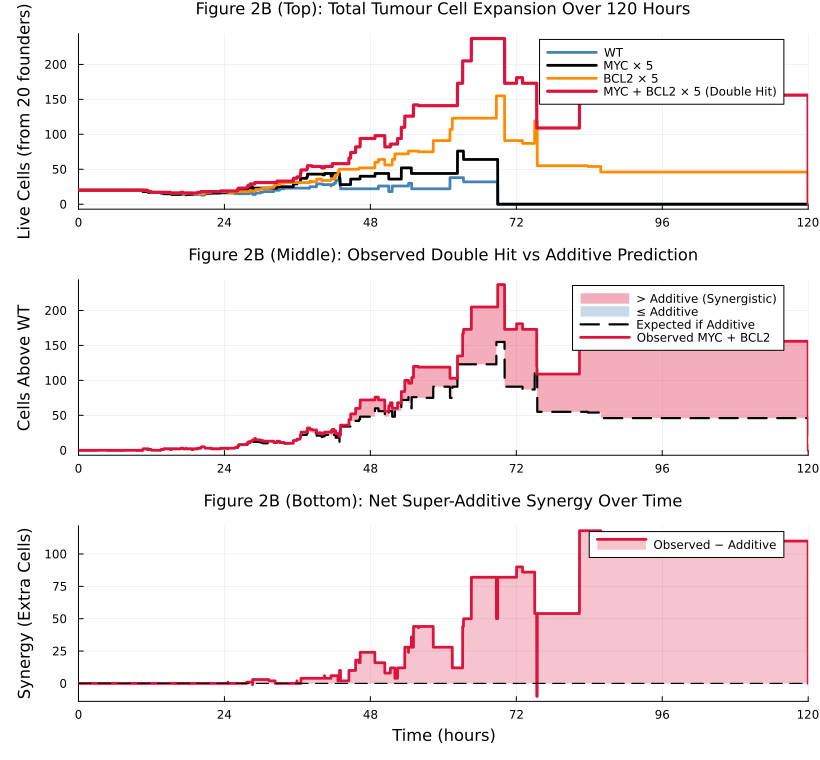

In [4]:
t_h = pop_bcl2["WT"].t_hours
wt  = pop_bcl2["WT"].total
myc = pop_bcl2["MYC × 5"].total
b2  = pop_bcl2["BCL2 × 5"].total
dh  = pop_bcl2["MYC + BCL2 × 5"].total

obs_over_wt = dh .- wt
add_over_wt = (myc .- wt) .+ (b2 .- wt)
synergy     = obs_over_wt .- add_over_wt

println("Peak observed DH over WT: ", round(maximum(obs_over_wt), digits=1), " cells")
println("Peak additive prediction: ", round(maximum(add_over_wt), digits=1), " cells")
println("Peak super-additive synergy: +", round(maximum(synergy), digits=1), " extra cells")

# Panel 1: Total cell numbers
p_tot = plot(t_h, wt,  lw=2.8, color=:steelblue, label="WT")
plot!(p_tot, t_h, myc, lw=2.8, color=:black,     label="MYC × 5")
plot!(p_tot, t_h, b2,  lw=2.8, color=:darkorange,label="BCL2 × 5")
plot!(p_tot, t_h, dh,  lw=3.2, color=:crimson,   label="MYC + BCL2 × 5 (Double Hit)")
plot!(p_tot, ylabel="Live Cells (from $(N_CELLS) founders)",
      title="Figure 2B (Top): Total Tumour Cell Expansion Over 120 Hours",
      titlefontsize=11, xlims=(0, 120), xticks=0:24:120, legend=:topright)

# Panel 2: Observed vs Additive with red (synergy) / blue (sub-additive) shading
hi_red  = max.(obs_over_wt, add_over_wt)
lo_blue = min.(obs_over_wt, add_over_wt)

p_add = plot(t_h, add_over_wt, fillrange=hi_red, fillalpha=0.35, fillcolor=:crimson,
             linealpha=0.0, label="> Additive (Synergistic)")
plot!(p_add, t_h, add_over_wt, fillrange=lo_blue, fillalpha=0.30, fillcolor=:steelblue,
      linealpha=0.0, label="≤ Additive")
plot!(p_add, t_h, add_over_wt, lw=2.2, color=:black, linestyle=:dash, label="Expected if Additive")
plot!(p_add, t_h, obs_over_wt, lw=2.8, color=:crimson, label="Observed MYC + BCL2")
plot!(p_add, ylabel="Cells Above WT",
      title="Figure 2B (Middle): Observed Double Hit vs Additive Prediction",
      titlefontsize=11, xlims=(0, 120), xticks=0:24:120, legend=:topright)

# Panel 3: Net Synergy curve (Observed - Additive)
p_syn = plot(t_h, synergy, lw=2.8, color=:crimson, fill=(0, 0.25, :crimson), label="Observed − Additive")
hline!(p_syn, [0.0], color=:black, linestyle=:dash, lw=1.2, label=false)
plot!(p_syn, xlabel="Time (hours)", ylabel="Synergy (Extra Cells)",
      title="Figure 2B (Bottom): Net Super-Additive Synergy Over Time",
      titlefontsize=11, xlims=(0, 120), xticks=0:24:120, legend=:topright)

plot(p_tot, p_add, p_syn, layout=(3, 1), size=(820, 760), left_margin=4Plots.mm)

### Why Do MYC and BCL2 Synergise So Strongly?

Look at the three panels together:
- **`WT`** peaks modestly around `38` cells (`1.9×` from 20 founders) around 43 h before apoptosis clears the population once the IKK pulse fades.
- **`MYC × 5`** accelerates G1 progression (`76` peak cells, `3.8×`), but apoptosis still limits how many generations cells survive.
- **`BCL2 × 5`** extends survival across the entire population (`155` peak cells, `7.75×`), allowing cells to keep dividing longer.
- **`MYC + BCL2 × 5`** reaches **`237` peak cells (`11.85×`)** — up to **`+118` more cells** than expected if the two mutations simply added together! Because population growth is **exponential** ($2^g$), combining a shorter division cycle (**PP**) with a longer survival window (**AA**) produces extra rounds of doubling that multiply the tumour burden.

---

## Interactive Exercise: Simulating Venetoclax in Double-Hit Lymphoma!

Clinically, the BH3 mimetic **venetoclax** inhibits anti-apoptotic **BCL2** in lymphoma cells. In our 193-species multiscale model, we can simulate adding venetoclax to a **`MYC + BCL2 × 5`** tumour by inhibiting mitochondrial BCL2 synthesis (`"k1_88-apoptosis" => 0.5`) — or test a milder **`1.5×`** copy-number gain (`k1_mycExp-linking => 1.5, k1_bcl2Exp-linking => 1.5`).

**Your task:** Run the cell below with `N_EX = 10` founder cells (fast — ~15 seconds!) and edit `intervention_mods` to see how strongly venetoclax (`"k1_88-apoptosis" => 0.5`) collapses the Double-Hit peak compared with an untreated `MYC + BCL2 × 5` tumour!

Row,Condition,Peak_Cells,Fold_Peak
,String,Int64,Float64
1,WT,38,3.8
2,MYC + BCL2 × 5 (untreated),157,15.7
3,MYC + BCL2 × 5 + My Drug,157,15.7


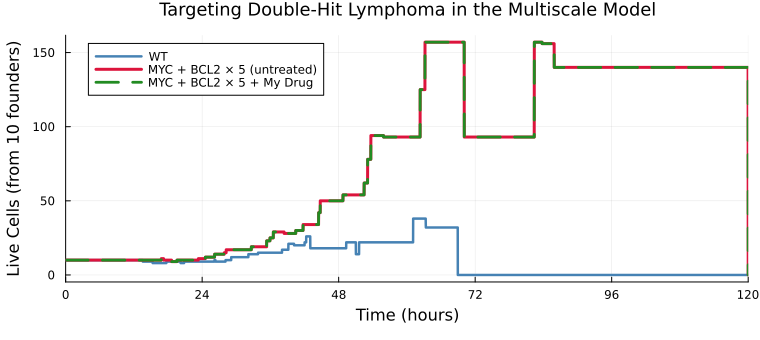

In [5]:
# Exercise: Test adding venetoclax ("k1_88-apoptosis" => 0.5) to MYC + BCL2 × 5!
const N_EX = 10

intervention_name = "MYC + BCL2 × 5 + My Drug"
intervention_mods = Dict(
    "k1_mycExp-linking"  => 5.0,
    "k1_bcl2Exp-linking" => 5.0,
    # <-- Uncomment the line below to simulate venetoclax (50% BCL2 inhibition):
    # "k1_88-apoptosis" => 0.5,
)

pop_wt_ex  = run_population(Dict{String, Float64}(), N_EX; preCV=0.11, seed=123)
pop_dh_ex  = run_population(Dict("k1_mycExp-linking" => 5.0, "k1_bcl2Exp-linking" => 5.0), N_EX; preCV=0.11, seed=123)
pop_int_ex = run_population(intervention_mods, N_EX; preCV=0.11, seed=123)

display(DataFrame(
    Condition  = ["WT", "MYC + BCL2 × 5 (untreated)", intervention_name],
    Peak_Cells = round.(Int, [maximum(pop_wt_ex.total), maximum(pop_dh_ex.total), maximum(pop_int_ex.total)]),
    Fold_Peak  = round.([maximum(pop_wt_ex.total), maximum(pop_dh_ex.total), maximum(pop_int_ex.total)] ./ N_EX, digits=2),
))

p_ex = plot(pop_wt_ex.t_hours,  pop_wt_ex.total,  lw=2.5, color=:steelblue, label="WT")
plot!(p_ex, pop_dh_ex.t_hours,  pop_dh_ex.total,  lw=3.0, color=:crimson,   label="MYC + BCL2 × 5 (untreated)")
plot!(p_ex, pop_int_ex.t_hours, pop_int_ex.total, lw=2.8, color=:forestgreen, linestyle=:dash, label=intervention_name)
plot!(p_ex, xlabel="Time (hours)", ylabel="Live Cells (from $(N_EX) founders)",
      title="Targeting Double-Hit Lymphoma in the Multiscale Model", titlefontsize=12,
      xlims=(0, 120), xticks=0:24:120, size=(760, 340))
p_ex

````{admonition} Hint
:class: dropdown tip

Uncomment `"k1_88-apoptosis" => 0.5` inside `intervention_mods` (simulating venetoclax), or try `"k1_88-apoptosis" => 0.25` for stronger BCL2 inhibition. You can also test a G1 CDK4/6 inhibitor (`"k1_20-cellCycle" => 0.7`) or combining both drugs!
````

````{admonition} Reveal Solution
:class: dropdown note

```julia
pop_ven = run_population(
    Dict("k1_mycExp-linking" => 5.0, "k1_bcl2Exp-linking" => 5.0, "k1_88-apoptosis" => 0.25),
    10; preCV=0.11, seed=123,
)
pop_cdk = run_population(
    Dict("k1_mycExp-linking" => 5.0, "k1_bcl2Exp-linking" => 5.0, "k1_20-cellCycle" => 0.7),
    10; preCV=0.11, seed=123,
)
println("Untreated DH peak: ", round(Int, maximum(pop_dh_ex.total)),
        " | + Venetoclax (0.25× BCL2): ", round(Int, maximum(pop_ven.total)),
        " | + CDK4/6 inh (0.7× RB-phos): ", round(Int, maximum(pop_cdk.total)))
```

Breaking *either* arm of the Double-Hit synergy — lowering the BCL2 survival brake (venetoclax) or slowing G1 progression (CDK4/6 inhibition) — sharply reduces peak tumour expansion!
````

Now continue to **[3. Why MYC + BCL6 Differs from MYC + BCL2 (Norris *et al.* Figure 2C)](./03-double-hit-myc-bcl6-vs-bcl2.ipynb)** to simulate the second classic double-hit combination and see why WHO 2022 reclassified it!